In [1]:
# Step 1 – Load the dataset
from pathlib import Path
import pandas as pd

project_root = Path.cwd().parent
data_path = project_root / "data" / "processed" / "final" / "churn_model_data.csv"

model_data = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", model_data.shape)

display(model_data.head())

print("\nTarget distribution:")
print(model_data["churned"].value_counts())

print("\nTarget percentage:")
print((model_data["churned"].value_counts(normalize=True) * 100).round(2))

Dataset loaded successfully!
Dataset shape: (6260, 73)


,customer_id,age,gender,country,city,acquisition_channel,customer_segment,preferred_language,tenure_days,total_viewing_sessions,...,customer_engagement_score,total_subscriptions_started,previously_ended_subscription_count,unique_plans_used_asof,has_used_multiple_plans_asof,current_plan_id_asof,monthly_price_asof,subscription_tenure_days_asof,churned,days_since_last_payment
0,CUST000744,21,Female,United Kingdom,Liverpool,Organic Search,Individual,English,2554,4.0,...,16.06,1,0,1,0,PLAN03,22.99,2554,False,2134
1,CUST001502,31,Male,Canada,Montreal,Referral,Family,French,138,5.0,...,33.62,1,0,1,0,PLAN01,6.99,138,False,18
2,CUST005383,40,Male,United Kingdom,Leeds,Paid Social,Student,English,1079,6.0,...,29.86,1,0,1,0,PLAN01,6.99,1079,False,659
3,CUST005877,36,Male,Indonesia,Jakarta,Email Campaign,Student,French,179,5.0,...,29.83,1,0,1,0,PLAN03,22.99,179,False,29
4,CUST003762,29,Male,Poland,Warsaw,App Store,Student,English,231,10.0,...,81.60,1,0,1,0,PLAN02,15.49,231,False,21



Target distribution:
churned
False    6009
True      251
Name: count, dtype: int64

Target percentage:
churned
False    95.99
True      4.01
Name: proportion, dtype: float64


In [2]:
# Step 2 – Separate features (X) and target (y)
X = model_data.drop(
    columns=["customer_id", "churned", "customer_engagement_score"]
)

y = model_data["churned"].astype(int)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical features:", X.select_dtypes(include="number").shape[1])
print("Categorical features:", X.select_dtypes(exclude="number").shape[1])

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (6260, 70)
Target shape: (6260,)

Numerical features: 56
Categorical features: 14

Target distribution:
churned
0    6009
1     251
Name: count, dtype: int64


In [3]:
# Step 3 – Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nTraining churn percentage:", round(y_train.mean() * 100, 2), "%")
print("Testing churn percentage:", round(y_test.mean() * 100, 2), "%")

Training feature shape: (5008, 70)
Testing feature shape: (1252, 70)

Training target distribution:
churned
0    4807
1     201
Name: count, dtype: int64

Testing target distribution:
churned
0    1202
1      50
Name: count, dtype: int64

Training churn percentage: 4.01 %
Testing churn percentage: 3.99 %


In [4]:
# Step 4 – Build the preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully!")

Numerical features: 56
Categorical features: 14
Preprocessing pipeline created successfully!


In [5]:
# Step 5 – Train Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


c:\Users\USER\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [6]:
# Step 5A – Improve the preprocessing pipeline
from sklearn.preprocessing import StandardScaler

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")
print("Iterations used:", logistic_model.named_steps["classifier"].n_iter_)

Logistic Regression model trained successfully!
Iterations used: [172]


In [7]:
# Step 6 – Evaluate Logistic Regression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("LOGISTIC REGRESSION - EVALUATION RESULTS")
print("-" * 45)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

LOGISTIC REGRESSION - EVALUATION RESULTS
---------------------------------------------
Accuracy: 0.7029
Precision: 0.0503
Recall: 0.36
F1 Score: 0.0882
ROC-AUC: 0.5413
PR-AUC: 0.0512

Confusion Matrix:
[[862 340]
 [ 32  18]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.72      0.82      1202
           1       0.05      0.36      0.09        50

    accuracy                           0.70      1252
   macro avg       0.51      0.54      0.46      1252
weighted avg       0.93      0.70      0.79      1252



In [8]:
# Step 7 – Train Random Forest
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [9]:
# Step 8 – Evaluate Random Forest
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("RANDOM FOREST - EVALUATION RESULTS")
print("-" * 45)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_rf), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

RANDOM FOREST - EVALUATION RESULTS
---------------------------------------------
Accuracy: 0.9601
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.5169
PR-AUC: 0.0751

Confusion Matrix:
[[1202    0]
 [  50    0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      1202
           1       0.00      0.00      0.00        50

    accuracy                           0.96      1252
   macro avg       0.48      0.50      0.49      1252
weighted avg       0.92      0.96      0.94      1252



c:\Users\USER\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\USER\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\USER\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\USER\anaconda3\Lib\site-packag

In [10]:
# Step 9 – Train Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ]
)

gradient_boosting_model.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights
)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [11]:
# Step 10 – Evaluate Gradient Boosting
y_pred_gb = gradient_boosting_model.predict(X_test)
y_prob_gb = gradient_boosting_model.predict_proba(X_test)[:, 1]

print("GRADIENT BOOSTING - EVALUATION RESULTS")
print("-" * 45)

print("Accuracy:", round(accuracy_score(y_test, y_pred_gb), 4))
print("Precision:", round(precision_score(y_test, y_pred_gb, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_gb, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_gb, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_gb), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_gb), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb, zero_division=0))

GRADIENT BOOSTING - EVALUATION RESULTS
---------------------------------------------
Accuracy: 0.7987
Precision: 0.057
Recall: 0.26
F1 Score: 0.0935
ROC-AUC: 0.5475
PR-AUC: 0.0774

Confusion Matrix:
[[987 215]
 [ 37  13]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.82      0.89      1202
           1       0.06      0.26      0.09        50

    accuracy                           0.80      1252
   macro avg       0.51      0.54      0.49      1252
weighted avg       0.93      0.80      0.86      1252



In [12]:
# Step 11 – Train XGBoost
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgboost_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgboost_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")
print("Scale positive weight:", round(scale_pos_weight, 2))

XGBoost model trained successfully!
Scale positive weight: 23.92


In [13]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [14]:
import xgboost

print("XGBoost version:", xgboost.__version__)
print("XGBoost installed successfully!")

XGBoost version: 3.4.1
XGBoost installed successfully!


In [15]:
# Step 11 – Train the XGBoost model
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgboost_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgboost_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")
print("Scale positive weight:", round(scale_pos_weight, 2))

XGBoost model trained successfully!
Scale positive weight: 23.92


In [16]:
# Step 12 – Evaluate XGBoost
y_pred_xgb = xgboost_model.predict(X_test)
y_prob_xgb = xgboost_model.predict_proba(X_test)[:, 1]

print("XGBOOST - EVALUATION RESULTS")
print("-" * 45)

print("Accuracy:", round(accuracy_score(y_test, y_pred_xgb), 4))
print("Precision:", round(precision_score(y_test, y_pred_xgb, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_xgb, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_xgb, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_xgb), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_xgb), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb, zero_division=0))

XGBOOST - EVALUATION RESULTS
---------------------------------------------
Accuracy: 0.8922
Precision: 0.0874
Recall: 0.18
F1 Score: 0.1176
ROC-AUC: 0.5469
PR-AUC: 0.0742

Confusion Matrix:
[[1108   94]
 [  41    9]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.92      0.94      1202
           1       0.09      0.18      0.12        50

    accuracy                           0.89      1252
   macro avg       0.53      0.55      0.53      1252
weighted avg       0.93      0.89      0.91      1252



In [17]:
# Step 13 – Compare all four models
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],
    "Accuracy": [0.7029, 0.9601, 0.7987, 0.8922],
    "Precision": [0.0503, 0, 0.0570, 0.0874],
    "Recall": [0.3600, 0, 0.2600, 0.1800],
    "F1 Score": [0.0882, 0, 0.0935, 0.1176],
    "ROC-AUC": [0.5413, 0.5169, 0.5475, 0.5469],
    "PR-AUC": [0.0512, 0.0751, 0.0774, 0.0742]
})

display(model_comparison)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.7029,0.0503,0.36,0.0882,0.5413,0.0512
1,Random Forest,0.9601,0.0000,0.00,0.0000,0.5169,0.0751
2,Gradient Boosting,0.7987,0.0570,0.26,0.0935,0.5475,0.0774
3,XGBoost,0.8922,0.0874,0.18,0.1176,0.5469,0.0742


In [18]:
display(model_comparison.style.hide(axis="index"))

Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.702900,0.050300,0.360000,0.088200,0.541300,0.051200
Random Forest,0.960100,0.000000,0.000000,0.000000,0.516900,0.075100
Gradient Boosting,0.798700,0.057000,0.260000,0.093500,0.547500,0.077400
XGBoost,0.892200,0.087400,0.180000,0.117600,0.546900,0.074200


In [19]:
# Step 14 – Create a validation dataset
X_train_fit, X_valid, y_train_fit, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model training data:", X_train_fit.shape)
print("Validation data:", X_valid.shape)

print("\nTraining churn distribution:")
print(y_train_fit.value_counts())

print("\nValidation churn distribution:")
print(y_valid.value_counts())

Model training data: (4006, 70)
Validation data: (1002, 70)

Training churn distribution:
churned
0    3845
1     161
Name: count, dtype: int64

Validation churn distribution:
churned
0    962
1     40
Name: count, dtype: int64


In [20]:
# Step 15 – Train Logistic Regression on training data
def create_preprocessor():
    numeric_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]
    )

    return ColumnTransformer(
        transformers=[
            ("numerical", numeric_transformer, numeric_features),
            ("categorical", categorical_transformer, categorical_features)
        ]
    )

logistic_validation_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        ))
    ]
)

logistic_validation_model.fit(X_train_fit, y_train_fit)

print("Logistic Regression validation model trained successfully!")

Logistic Regression validation model trained successfully!


In [21]:
# Step 16 – Train Random Forest
random_forest_validation_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_validation_model.fit(X_train_fit, y_train_fit)

print("Random Forest validation model trained successfully!")

Random Forest validation model trained successfully!


In [22]:
random_forest_validation_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_validation_model.fit(X_train_fit, y_train_fit)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](70,)","['age','gender','country',...,'monthly_price_asof', 'subscription_tenure_days_asof','days_since_last_payment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,70
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of `

In [23]:
y_pred_rf_valid = random_forest_validation_model.predict(X_valid)
y_prob_rf_valid = random_forest_validation_model.predict_proba(X_valid)[:, 1]

print("RANDOM FOREST - VALIDATION RESULTS")
print("-" * 45)

print("Accuracy:", round(accuracy_score(y_valid, y_pred_rf_valid), 4))
print("Precision:", round(precision_score(y_valid, y_pred_rf_valid, zero_division=0), 4))
print("Recall:", round(recall_score(y_valid, y_pred_rf_valid, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_valid, y_pred_rf_valid, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_valid, y_prob_rf_valid), 4))
print("PR-AUC:", round(average_precision_score(y_valid, y_prob_rf_valid), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_valid, y_pred_rf_valid))

RANDOM FOREST - VALIDATION RESULTS
---------------------------------------------
Accuracy: 0.9601
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.5531
PR-AUC: 0.0594

Confusion Matrix:
[[962   0]
 [ 40   0]]


In [24]:
# Step 19 – Logistic Regression validation evaluation
y_pred_lr_valid = logistic_validation_model.predict(X_valid)
y_prob_lr_valid = logistic_validation_model.predict_proba(X_valid)[:, 1]

print("LOGISTIC REGRESSION - VALIDATION RESULTS")
print("-" * 45)

print("Accuracy:", round(accuracy_score(y_valid, y_pred_lr_valid), 4))
print("Precision:", round(precision_score(y_valid, y_pred_lr_valid, zero_division=0), 4))
print("Recall:", round(recall_score(y_valid, y_pred_lr_valid, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_valid, y_pred_lr_valid, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_valid, y_prob_lr_valid), 4))
print("PR-AUC:", round(average_precision_score(y_valid, y_prob_lr_valid), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_valid, y_pred_lr_valid))

LOGISTIC REGRESSION - VALIDATION RESULTS
---------------------------------------------
Accuracy: 0.7345
Precision: 0.0292
Recall: 0.175
F1 Score: 0.05
ROC-AUC: 0.458
PR-AUC: 0.0507

Confusion Matrix:
[[729 233]
 [ 33   7]]


In [25]:
print("Gradient Boosting model exists:", "gradient_boosting_validation_model" in globals())

Gradient Boosting model exists: False


In [26]:
# Step 21 – Train Gradient Boosting validation model
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

sample_weights_valid = compute_sample_weight(
    class_weight="balanced",
    y=y_train_fit
)

gradient_boosting_validation_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ]
)

gradient_boosting_validation_model.fit(
    X_train_fit,
    y_train_fit,
    classifier__sample_weight=sample_weights_valid
)

print("Gradient Boosting validation model trained successfully!")

Gradient Boosting validation model trained successfully!


In [27]:
# Step 22 – Evaluate Gradient Boosting
y_pred_gb_valid = gradient_boosting_validation_model.predict(X_valid)
y_prob_gb_valid = gradient_boosting_validation_model.predict_proba(X_valid)[:, 1]

print("GRADIENT BOOSTING - VALIDATION RESULTS")
print("-" * 45)

print("Accuracy:", round(accuracy_score(y_valid, y_pred_gb_valid), 4))
print("Precision:", round(precision_score(y_valid, y_pred_gb_valid, zero_division=0), 4))
print("Recall:", round(recall_score(y_valid, y_pred_gb_valid, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_valid, y_pred_gb_valid, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_valid, y_prob_gb_valid), 4))
print("PR-AUC:", round(average_precision_score(y_valid, y_prob_gb_valid), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_valid, y_pred_gb_valid))

GRADIENT BOOSTING - VALIDATION RESULTS
---------------------------------------------
Accuracy: 0.8064
Precision: 0.0471
Recall: 0.2
F1 Score: 0.0762
ROC-AUC: 0.5104
PR-AUC: 0.0679

Confusion Matrix:
[[800 162]
 [ 32   8]]


In [28]:
# Step 24 – Check XGBoost validation model
print("XGBoost validation model exists:", "xgboost_validation_model" in globals())

XGBoost validation model exists: False


In [29]:
from xgboost import XGBClassifier

scale_pos_weight_valid = (
    (y_train_fit == 0).sum() / (y_train_fit == 1).sum()
)

xgboost_validation_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight_valid,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgboost_validation_model.fit(X_train_fit, y_train_fit)

print("XGBoost validation model trained successfully!")
print("Scale positive weight:", round(scale_pos_weight_valid, 2))

XGBoost validation model trained successfully!
Scale positive weight: 23.88


In [30]:
y_pred_xgb_valid = xgboost_validation_model.predict(X_valid)
y_prob_xgb_valid = xgboost_validation_model.predict_proba(X_valid)[:, 1]

print("XGBOOST - VALIDATION RESULTS")
print("-" * 45)

print("Accuracy:", round(accuracy_score(y_valid, y_pred_xgb_valid), 4))
print("Precision:", round(precision_score(y_valid, y_pred_xgb_valid, zero_division=0), 4))
print("Recall:", round(recall_score(y_valid, y_pred_xgb_valid, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_valid, y_pred_xgb_valid, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_valid, y_prob_xgb_valid), 4))
print("PR-AUC:", round(average_precision_score(y_valid, y_prob_xgb_valid), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_valid, y_pred_xgb_valid))

XGBOOST - VALIDATION RESULTS
---------------------------------------------
Accuracy: 0.9012
Precision: 0.0462
Recall: 0.075
F1 Score: 0.0571
ROC-AUC: 0.5432
PR-AUC: 0.0595

Confusion Matrix:
[[900  62]
 [ 37   3]]


In [31]:
# Step 29 – Evaluate different classification thresholds
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (
        y_prob_gb_valid >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_valid, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, y_pred_threshold, zero_division=0
        ),
        "F1 Score": f1_score(
            y_valid, y_pred_threshold, zero_division=0
        )
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.05,0.0379,0.925,0.0729
1,0.10,0.0396,0.900,0.0759
2,0.15,0.0405,0.825,0.0773
3,0.20,0.0402,0.725,0.0761
4,0.25,0.0417,0.650,0.0784
5,0.30,0.0432,0.550,0.0801
6,0.40,0.0418,0.325,0.0741
7,0.50,0.0471,0.200,0.0762


In [32]:
# Step 31 – Check the confusion matrix at threshold 0.30
selected_threshold = 0.30

y_pred_gb_selected = (
    y_prob_gb_valid >= selected_threshold
).astype(int)

print("GRADIENT BOOSTING - THRESHOLD 0.30")
print("-" * 45)

print("Confusion Matrix:")
print(confusion_matrix(y_valid, y_pred_gb_selected))

print("\nCustomers flagged:", y_pred_gb_selected.sum())
print("Actual churners identified:", ((y_valid == 1) & (y_pred_gb_selected == 1)).sum())
print("False positives:", ((y_valid == 0) & (y_pred_gb_selected == 1)).sum())
print("Missed churners:", ((y_valid == 1) & (y_pred_gb_selected == 0)).sum())

GRADIENT BOOSTING - THRESHOLD 0.30
---------------------------------------------
Confusion Matrix:
[[475 487]
 [ 18  22]]

Customers flagged: 509
Actual churners identified: 22
False positives: 487
Missed churners: 18


In [33]:
# Step 33 – Compare business trade-offs across thresholds
threshold_business_results = []

for threshold in thresholds:
    predictions = (y_prob_gb_valid >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, predictions
    ).ravel()

    threshold_business_results.append({
        "Threshold": threshold,
        "Customers Flagged": int(tp + fp),
        "Actual Churners Identified": int(tp),
        "False Positives": int(fp),
        "Missed Churners": int(fn),
        "Recall": round(recall_score(y_valid, predictions), 4),
        "Precision": round(precision_score(y_valid, predictions, zero_division=0), 4)
    })

business_threshold_comparison = pd.DataFrame(
    threshold_business_results
)

display(business_threshold_comparison)

,Threshold,Customers Flagged,Actual Churners Identified,False Positives,Missed Churners,Recall,Precision
0,0.05,975,37,938,3,0.925,0.0379
1,0.10,909,36,873,4,0.900,0.0396
2,0.15,814,33,781,7,0.825,0.0405
3,0.20,722,29,693,11,0.725,0.0402
4,0.25,623,26,597,14,0.650,0.0417
5,0.30,509,22,487,18,0.550,0.0432
6,0.40,311,13,298,27,0.325,0.0418
7,0.50,170,8,162,32,0.200,0.0471


In [34]:
# Step 34: Threshold tuning for XGBoost
xgb_threshold_results = []

for threshold in thresholds:
    predictions = (y_prob_xgb_valid >= threshold).astype(int)

    xgb_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_valid, predictions, zero_division=0),
        "Recall": recall_score(y_valid, predictions, zero_division=0),
        "F1 Score": f1_score(y_valid, predictions, zero_division=0)
    })

xgb_threshold_comparison = pd.DataFrame(xgb_threshold_results)

display(xgb_threshold_comparison.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.05,0.0403,0.775,0.0765
1,0.10,0.0385,0.575,0.0722
2,0.15,0.0481,0.550,0.0885
3,0.20,0.0515,0.475,0.0929
4,0.25,0.0503,0.375,0.0888
5,0.30,0.0548,0.300,0.0927
6,0.40,0.0684,0.200,0.1019
7,0.50,0.0462,0.075,0.0571


In [35]:
# XGBoost business impact
xgb_business_results = []

for threshold in thresholds:
    predictions = (y_prob_xgb_valid >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid,
        predictions
    ).ravel()

    xgb_business_results.append({
        "Threshold": threshold,
        "Customers Flagged": tp + fp,
        "Actual Churners Identified": tp,
        "False Positives": fp,
        "Missed Churners": fn
    })

xgb_business_comparison = pd.DataFrame(xgb_business_results)

display(xgb_business_comparison)


,Threshold,Customers Flagged,Actual Churners Identified,False Positives,Missed Churners
0,0.05,770,31,739,9
1,0.10,597,23,574,17
2,0.15,457,22,435,18
3,0.20,369,19,350,21
4,0.25,298,15,283,25
5,0.30,219,12,207,28
6,0.40,117,8,109,32
7,0.50,65,3,62,37


In [36]:
# Compare Logistic Regression and Random Forest thresholds
logistic_prob_valid = logistic_validation_model.predict_proba(X_valid)[:, 1]
rf_prob_valid = random_forest_validation_model.predict_proba(X_valid)[:, 1]

print("Logistic Regression probabilities:")
print(pd.Series(logistic_prob_valid).describe())

print("\nRandom Forest probabilities:")
print(pd.Series(rf_prob_valid).describe())

Logistic Regression probabilities:
count    1002.000000
mean        0.296861
std         0.276956
min         0.000018
25%         0.060940
50%         0.200656
75%         0.478722
max         0.989869
dtype: float64

Random Forest probabilities:
count    1002.000000
mean        0.043490
std         0.040695
min         0.000000
25%         0.016667
50%         0.033333
75%         0.053333
max         0.323333
dtype: float64


In [37]:
logistic_threshold_results = []

for threshold in thresholds:
    predictions = (logistic_prob_valid >= threshold).astype(int)

    logistic_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_valid, predictions, zero_division=0),
        "Recall": recall_score(y_valid, predictions, zero_division=0),
        "F1 Score": f1_score(y_valid, predictions, zero_division=0)
    })

logistic_threshold_comparison = pd.DataFrame(logistic_threshold_results)

display(logistic_threshold_comparison.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.05,0.0384,0.750,0.0731
1,0.10,0.0332,0.550,0.0626
2,0.15,0.0329,0.475,0.0615
3,0.20,0.0319,0.400,0.0590
4,0.25,0.0315,0.350,0.0577
5,0.30,0.0327,0.325,0.0594
6,0.40,0.0357,0.275,0.0632
7,0.50,0.0292,0.175,0.0500


In [38]:
# Next step: Random Forest threshold tuning
rf_thresholds = [0.01, 0.02, 0.03, 0.04, 0.05, 0.075, 0.10, 0.15, 0.20, 0.25]

rf_threshold_results = []

for threshold in rf_thresholds:
    predictions = (rf_prob_valid >= threshold).astype(int)

    rf_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_valid, predictions, zero_division=0),
        "Recall": recall_score(y_valid, predictions, zero_division=0),
        "F1 Score": f1_score(y_valid, predictions, zero_division=0)
    })

rf_threshold_comparison = pd.DataFrame(rf_threshold_results)

display(rf_threshold_comparison.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.010,0.0409,0.950,0.0785
1,0.020,0.0442,0.825,0.0839
2,0.030,0.0424,0.575,0.0789
3,0.040,0.0530,0.550,0.0967
4,0.050,0.0557,0.425,0.0986
5,0.075,0.0403,0.150,0.0635
6,0.100,0.0494,0.100,0.0661
7,0.150,0.0690,0.050,0.0580
8,0.200,0.2000,0.050,0.0800
9,0.250,0.2000,0.025,0.0444


In [39]:
# Next step: Random Forest business impact
rf_business_results = []

for threshold in rf_thresholds:
    predictions = (rf_prob_valid >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid,
        predictions
    ).ravel()

    rf_business_results.append({
        "Threshold": threshold,
        "Customers Flagged": tp + fp,
        "Actual Churners Identified": tp,
        "False Positives": fp,
        "Missed Churners": fn
    })

rf_business_comparison = pd.DataFrame(rf_business_results)

display(rf_business_comparison)

,Threshold,Customers Flagged,Actual Churners Identified,False Positives,Missed Churners
0,0.010,928,38,890,2
1,0.020,747,33,714,7
2,0.030,543,23,520,17
3,0.040,415,22,393,18
4,0.050,305,17,288,23
5,0.075,149,6,143,34
6,0.100,81,4,77,36
7,0.150,29,2,27,38
8,0.200,10,2,8,38
9,0.250,5,1,4,39


In [40]:
# Next step: Cross-validation
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision"
}

print("Cross-validation setup completed.")
print("Number of folds:", cv.get_n_splits())
print("Training data shape:", X_train.shape)
print("Training churn distribution:")
print(y_train.value_counts())

Cross-validation setup completed.
Number of folds: 5
Training data shape: (5008, 70)
Training churn distribution:
churned
0    4807
1     201
Name: count, dtype: int64


In [41]:
# Next step: Cross-validate Logistic Regression
logistic_cv_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        ))
    ]
)

logistic_cv_results = cross_validate(
    logistic_cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

logistic_cv_summary = pd.DataFrame({
    "Metric": scoring.keys(),
    "Mean": [
        logistic_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Standard Deviation": [
        logistic_cv_results[f"test_{metric}"].std()
        for metric in scoring
    ]
})

display(logistic_cv_summary.round(4))

,Metric,Mean,Standard Deviation
0,average_precision,0.0745,0.0219
1,roc_auc,0.5717,0.0252
2,f1,0.0915,0.0133
3,recall,0.3428,0.0584
4,precision,0.0528,0.0075


In [42]:
# Random Forest cross-validation
random_forest_cv_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=1
        ))
    ]
)

random_forest_cv_results = cross_validate(
    random_forest_cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

random_forest_cv_summary = pd.DataFrame({
    "Metric": scoring.keys(),
    "Mean": [
        random_forest_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Standard Deviation": [
        random_forest_cv_results[f"test_{metric}"].std()
        for metric in scoring
    ]
})

display(random_forest_cv_summary.round(4))

,Metric,Mean,Standard Deviation
0,average_precision,0.1093,0.0297
1,roc_auc,0.6302,0.0110
2,f1,0.0000,0.0000
3,recall,0.0000,0.0000
4,precision,0.0000,0.0000


In [44]:
# Gradient Boosting cross-validation
gradient_boosting_cv_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ]
)

gradient_boosting_cv_results = cross_validate(
    estimator=gradient_boosting_cv_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

gradient_boosting_cv_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean": [
        gradient_boosting_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Standard Deviation": [
        gradient_boosting_cv_results[f"test_{metric}"].std()
        for metric in scoring
    ]
})

display(gradient_boosting_cv_summary.round(4))

display(gradient_boosting_cv_summary.round(4))

,Metric,Mean,Standard Deviation
0,average_precision,0.0787,0.0229
1,roc_auc,0.6082,0.0216
2,f1,0.0265,0.0346
3,recall,0.0148,0.0196
4,precision,0.1667,0.2108


,Metric,Mean,Standard Deviation
0,average_precision,0.0787,0.0229
1,roc_auc,0.6082,0.0216
2,f1,0.0265,0.0346
3,recall,0.0148,0.0196
4,precision,0.1667,0.2108


In [45]:
# Next: XGBoost 5-Fold Cross-Validation
scale_pos_weight_cv = (
    (y_train == 0).sum() / (y_train == 1).sum()
)

xgboost_cv_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight_cv,
            eval_metric="logloss",
            random_state=42,
            n_jobs=1
        ))
    ]
)

xgboost_cv_results = cross_validate(
    estimator=xgboost_cv_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

xgboost_cv_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean": [
        xgboost_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Standard Deviation": [
        xgboost_cv_results[f"test_{metric}"].std()
        for metric in scoring
    ]
})

display(xgboost_cv_summary.round(4))

,Metric,Mean,Standard Deviation
0,average_precision,0.0806,0.0166
1,roc_auc,0.6012,0.0280
2,f1,0.1007,0.0243
3,recall,0.1194,0.0331
4,precision,0.0879,0.0197


In [46]:
# Create a consolidated CV comparison
cv_model_summaries = {
    "Logistic Regression": logistic_cv_results,
    "Random Forest": random_forest_cv_results,
    "Gradient Boosting": gradient_boosting_cv_results,
    "XGBoost": xgboost_cv_results
}

cv_comparison = []

for model_name, results in cv_model_summaries.items():
    cv_comparison.append({
        "Model": model_name,
        "PR-AUC": results["test_average_precision"].mean(),
        "ROC-AUC": results["test_roc_auc"].mean(),
        "F1": results["test_f1"].mean(),
        "Recall": results["test_recall"].mean(),
        "Precision": results["test_precision"].mean()
    })

cv_comparison_df = pd.DataFrame(cv_comparison)

display(
    cv_comparison_df
    .sort_values("PR-AUC", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

,Model,PR-AUC,ROC-AUC,F1,Recall,Precision
0,Random Forest,0.1093,0.6302,0.0000,0.0000,0.0000
1,XGBoost,0.0806,0.6012,0.1007,0.1194,0.0879
2,Gradient Boosting,0.0787,0.6082,0.0265,0.0148,0.1667
3,Logistic Regression,0.0745,0.5717,0.0915,0.3428,0.0528


In [47]:
model_selection_summary = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "CV PR-AUC": 0.0745,
        "CV ROC-AUC": 0.5717,
        "CV F1": 0.0915,
        "Best Validation Threshold": 0.05,
        "Validation Precision": 0.0384,
        "Validation Recall": 0.7500,
        "Validation F1": 0.0731
    },
    {
        "Model": "Random Forest",
        "CV PR-AUC": 0.1093,
        "CV ROC-AUC": 0.6302,
        "CV F1": 0.0000,
        "Best Validation Threshold": 0.05,
        "Validation Precision": 0.0557,
        "Validation Recall": 0.4250,
        "Validation F1": 0.0986
    },
    {
        "Model": "Gradient Boosting",
        "CV PR-AUC": 0.0787,
        "CV ROC-AUC": 0.6082,
        "CV F1": 0.0265,
        "Best Validation Threshold": 0.30,
        "Validation Precision": 0.0432,
        "Validation Recall": 0.5500,
        "Validation F1": 0.0801
    },
    {
        "Model": "XGBoost",
        "CV PR-AUC": 0.0806,
        "CV ROC-AUC": 0.6012,
        "CV F1": 0.1007,
        "Best Validation Threshold": 0.40,
        "Validation Precision": 0.0684,
        "Validation Recall": 0.2000,
        "Validation F1": 0.1019
    }
])

display(
    model_selection_summary
    .sort_values("CV PR-AUC", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

,Model,CV PR-AUC,CV ROC-AUC,CV F1,Best Validation Threshold,Validation Precision,Validation Recall,Validation F1
0,Random Forest,0.1093,0.6302,0.0000,0.05,0.0557,0.425,0.0986
1,XGBoost,0.0806,0.6012,0.1007,0.40,0.0684,0.200,0.1019
2,Gradient Boosting,0.0787,0.6082,0.0265,0.30,0.0432,0.550,0.0801
3,Logistic Regression,0.0745,0.5717,0.0915,0.05,0.0384,0.750,0.0731


In [48]:
# Next step: Compare actual business impact
business_model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Threshold": 0.05,
        "Customers Flagged": 750,
        "Actual Churners Identified": 30,
        "False Positives": 720,
        "Missed Churners": 10
    },
    {
        "Model": "Random Forest",
        "Threshold": 0.05,
        "Customers Flagged": 305,
        "Actual Churners Identified": 17,
        "False Positives": 288,
        "Missed Churners": 23
    },
    {
        "Model": "Gradient Boosting",
        "Threshold": 0.30,
        "Customers Flagged": 509,
        "Actual Churners Identified": 22,
        "False Positives": 487,
        "Missed Churners": 18
    },
    {
        "Model": "XGBoost",
        "Threshold": 0.40,
        "Customers Flagged": 117,
        "Actual Churners Identified": 8,
        "False Positives": 109,
        "Missed Churners": 32
    }
])

display(business_model_comparison)

,Model,Threshold,Customers Flagged,Actual Churners Identified,False Positives,Missed Churners
0,Logistic Regression,0.05,750,30,720,10
1,Random Forest,0.05,305,17,288,23
2,Gradient Boosting,0.30,509,22,487,18
3,XGBoost,0.40,117,8,109,32


In [50]:

import numpy as np
import pandas as pd

campaign_capacities = [100, 200, 300, 400, 500, 600, 750]

model_probabilities = {
    "Logistic Regression": logistic_prob_valid,
    "Random Forest": rf_prob_valid,
    "Gradient Boosting": y_prob_gb_valid,
    "XGBoost": y_prob_xgb_valid
}

campaign_results = []

for model_name, probabilities in model_probabilities.items():

    sorted_indices = np.argsort(probabilities)[::-1]

    for capacity in campaign_capacities:
        selected_indices = sorted_indices[:capacity]

        actual_churners = y_valid.iloc[selected_indices].sum()
        false_positives = capacity - actual_churners
        missed_churners = y_valid.sum() - actual_churners

        campaign_results.append({
            "Model": model_name,
            "Campaign Capacity": capacity,
            "Customers Flagged": capacity,
            "Actual Churners Identified": actual_churners,
            "False Positives": false_positives,
            "Missed Churners": missed_churners,
            "Precision": actual_churners / capacity,
            "Recall": actual_churners / y_valid.sum()
        })

campaign_comparison = pd.DataFrame(campaign_results)

display(campaign_comparison.round(4))

,Model,Campaign Capacity,Customers Flagged,Actual Churners Identified,False Positives,Missed Churners,Precision,Recall
0,Logistic Regression,100,100,4,96,36,0.0400,0.100
1,Logistic Regression,200,200,7,193,33,0.0350,0.175
2,Logistic Regression,300,300,11,289,29,0.0367,0.275
3,Logistic Regression,400,400,13,387,27,0.0325,0.325
4,Logistic Regression,500,500,16,484,24,0.0320,0.400
5,Logistic Regression,600,600,19,581,21,0.0317,0.475
6,Logistic Regression,750,750,28,722,12,0.0373,0.700
7,Random Forest,100,100,4,96,36,0.0400,0.100
8,Random Forest,200,200,7,193,33,0.0350,0.175
9,Random Forest,300,300,16,284,24,0.0533,0.400


In [51]:
# Next step: Find the best model for each campaign capacity
capacity_winners = (
    campaign_comparison
    .sort_values(
        ["Campaign Capacity", "Actual Churners Identified", "Precision"],
        ascending=[True, False, False]
    )
    .groupby("Campaign Capacity")
    .head(1)
    .reset_index(drop=True)
)

display(
    capacity_winners[
        [
            "Campaign Capacity",
            "Model",
            "Actual Churners Identified",
            "False Positives",
            "Missed Churners",
            "Precision",
            "Recall"
        ]
    ].round(4)
)

,Campaign Capacity,Model,Actual Churners Identified,False Positives,Missed Churners,Precision,Recall
0,100,XGBoost,6,94,34,0.0600,0.150
1,200,XGBoost,12,188,28,0.0600,0.300
2,300,Random Forest,16,284,24,0.0533,0.400
3,400,Random Forest,21,379,19,0.0525,0.525
4,500,Random Forest,23,477,17,0.0460,0.575
5,600,Gradient Boosting,26,574,14,0.0433,0.650
6,750,Random Forest,33,717,7,0.0440,0.825


In [52]:
# Select the campaign capacity
selected_capacity = 300

selected_campaign = campaign_comparison[
    campaign_comparison["Campaign Capacity"] == selected_capacity
].sort_values(
    ["Actual Churners Identified", "Precision"],
    ascending=False
).iloc[0]

print("Selected Campaign Capacity:", selected_capacity)
print("Recommended Model:", selected_campaign["Model"])
print("Customers Flagged:", selected_campaign["Customers Flagged"])
print("Actual Churners Identified:", selected_campaign["Actual Churners Identified"])
print("False Positives:", selected_campaign["False Positives"])
print("Missed Churners:", selected_campaign["Missed Churners"])
print("Precision:", round(selected_campaign["Precision"], 4))
print("Recall:", round(selected_campaign["Recall"], 4))

Selected Campaign Capacity: 300
Recommended Model: Random Forest
Customers Flagged: 300
Actual Churners Identified: 16
False Positives: 284
Missed Churners: 24
Precision: 0.0533
Recall: 0.4


In [53]:
# Refit Random Forest on the complete training set
final_random_forest_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

final_random_forest_model.fit(X_train, y_train)

print("Final Random Forest model trained successfully.")
print("Training records:", X_train.shape[0])
print("Number of features:", X_train.shape[1])


Final Random Forest model trained successfully.
Training records: 5008
Number of features: 70


In [54]:
# Evaluate the campaign on the test set
y_prob_test = final_random_forest_model.predict_proba(X_test)[:, 1]

test_campaign_indices = np.argsort(y_prob_test)[::-1][:300]

y_test_campaign = y_test.iloc[test_campaign_indices]

actual_churners = y_test_campaign.sum()
false_positives = len(test_campaign_indices) - actual_churners
missed_churners = y_test.sum() - actual_churners

precision = actual_churners / len(test_campaign_indices)
recall = actual_churners / y_test.sum()

print("Campaign Capacity:", len(test_campaign_indices))
print("Actual Churners Identified:", actual_churners)
print("False Positives:", false_positives)
print("Missed Churners:", missed_churners)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

Campaign Capacity: 300
Actual Churners Identified: 14
False Positives: 286
Missed Churners: 36
Precision: 0.0467
Recall: 0.28


In [55]:
y_pred_test = final_random_forest_model.predict(X_test)

print(classification_report(y_test, y_pred_test, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_test), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_test), 4))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98      1202
           1       0.00      0.00      0.00        50

    accuracy                           0.96      1252
   macro avg       0.48      0.50      0.49      1252
weighted avg       0.92      0.96      0.94      1252

ROC-AUC: 0.5169
PR-AUC: 0.0751


In [56]:
logistic_final_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        ))
    ]
)

logistic_final_model.fit(X_train, y_train)

sample_weights_final = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

gradient_boosting_final_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ]
)

gradient_boosting_final_model.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights_final
)

scale_pos_weight_final = (
    (y_train == 0).sum() / (y_train == 1).sum()
)

xgboost_final_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight_final,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgboost_final_model.fit(X_train, y_train)

print("All four models are ready for test-set campaign comparison.")

All four models are ready for test-set campaign comparison.


In [57]:
final_models = {
    "Logistic Regression": logistic_final_model,
    "Random Forest": final_random_forest_model,
    "Gradient Boosting": gradient_boosting_final_model,
    "XGBoost": xgboost_final_model
}

test_campaign_results = []

for model_name, model in final_models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    sorted_indices = np.argsort(probabilities)[::-1]
    selected_indices = sorted_indices[:300]

    actual_churners = y_test.iloc[selected_indices].sum()
    false_positives = 300 - actual_churners
    missed_churners = y_test.sum() - actual_churners

    precision = actual_churners / 300
    recall = actual_churners / y_test.sum()

    test_campaign_results.append({
        "Model": model_name,
        "Campaign Capacity": 300,
        "Churners Identified": actual_churners,
        "False Positives": false_positives,
        "Missed Churners": missed_churners,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4)
    })

test_campaign_comparison = pd.DataFrame(test_campaign_results)

test_campaign_comparison.sort_values(
    by=["Churners Identified", "Precision"],
    ascending=False
).reset_index(drop=True)

,Model,Campaign Capacity,Churners Identified,False Positives,Missed Churners,Precision,Recall
0,Gradient Boosting,300,17,283,33,0.0567,0.34
1,Logistic Regression,300,15,285,35,0.0500,0.30
2,Random Forest,300,14,286,36,0.0467,0.28
3,XGBoost,300,13,287,37,0.0433,0.26


Gradient Boosting - Final Test Evaluation
---------------------------------------------

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.96      0.82      0.89      1202
       Churn       0.06      0.26      0.09        50

    accuracy                           0.80      1252
   macro avg       0.51      0.54      0.49      1252
weighted avg       0.93      0.80      0.86      1252

ROC-AUC: 0.5475
PR-AUC: 0.0774


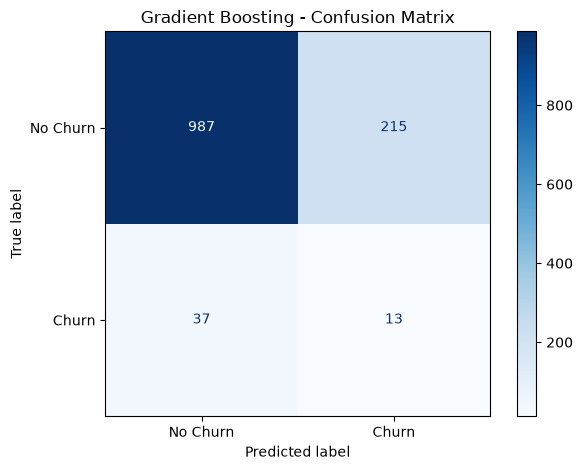

In [59]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

gb_y_prob_test = gradient_boosting_final_model.predict_proba(X_test)[:, 1]
gb_y_pred_test = gradient_boosting_final_model.predict(X_test)

print("Gradient Boosting - Final Test Evaluation")
print("-" * 45)

print("\nClassification Report:")
print(classification_report(
    y_test,
    gb_y_pred_test,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

print("ROC-AUC:", round(roc_auc_score(y_test, gb_y_prob_test), 4))
print("PR-AUC:", round(average_precision_score(y_test, gb_y_prob_test), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    gb_y_pred_test,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Gradient Boosting - Confusion Matrix")
plt.tight_layout()
plt.show()

In [60]:
new_customer = X_test.iloc[[0]].copy()

new_customer.index = ["NEW_CUSTOMER_001"]

print("New customer record created.")
print("Number of features:", new_customer.shape[1])
display(new_customer.T)

New customer record created.
Number of features: 70


,NEW_CUSTOMER_001
age,32
gender,Male
country,South Africa
city,Cape Town
acquisition_channel,Paid Social
...,...
has_used_multiple_plans_asof,0
current_plan_id_asof,PLAN01
monthly_price_asof,6.99
subscription_tenure_days_asof,1889


In [61]:
new_customer_prediction = gradient_boosting_final_model.predict(new_customer)

new_customer_probability = gradient_boosting_final_model.predict_proba(new_customer)

prediction_label = "Churn" if new_customer_prediction[0] == 1 else "No Churn"

print("Customer ID:", new_customer.index[0])
print("Predicted Result:", prediction_label)
print("No Churn Probability:", round(new_customer_probability[0][0] * 100, 2), "%")
print("Churn Probability:", round(new_customer_probability[0][1] * 100, 2), "%")

Customer ID: NEW_CUSTOMER_001
Predicted Result: No Churn
No Churn Probability: 89.01 %
Churn Probability: 10.99 %
